## Read embeddings

In [1]:
import pandas as pd
MODELS_DESCRIPTIONS = {
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }

}
selected_model = MODELS_DESCRIPTIONS["mix_of_alleles"]


In [2]:

selected_alleles = selected_model['alleles']
states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = 0
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [3]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [4]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [5]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Wall time: 25.8 s


# Hierarchical clustering of paths in the space of peptides

In [6]:
df = per_model_type_train_embeddings["v"].copy()
label_to_index = {label: i for i, label in enumerate(selected_alleles)}
df['label'] = df['allele'].map(label_to_index)
labels = selected_alleles

In [7]:
X = df.drop(columns=['allele', 'label', 'peptide']).values
TOP = 2000
X = X.T[:TOP]
print(f"Shape of data {X.shape}")

Shape of data (2000, 13336)


In [8]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

[]

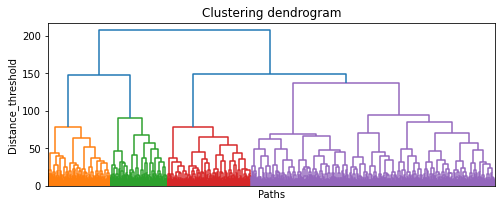

In [9]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Paths')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [10]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=150
)
model.fit(X)

AgglomerativeClustering(distance_threshold=150, n_clusters=None)

In [11]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
path_to_label = {i:model.labels_[i] for i in range(X.shape[0])}
unique_labels_counts

0    1464
1     536
dtype: int64

In [12]:
peptide_df = pd.DataFrame({"peptide": df.index.values, "allele": df['allele']})

In [13]:
for label in unique_labels_counts.index:
    # peptide_df[f'path_gr_{label}'] = np.exp(df[ [path for path, cur_label in path_to_label.items() if cur_label == label]]).mean(axis=1).values
    peptide_df[f'path_gr_{label}'] = df[[str(path) for path, cur_label in path_to_label.items() if cur_label == label]].max(axis=1).values


In [14]:
peptide_df['max_label'] = peptide_df[[f'path_gr_{label}' for label in path_to_label.values()]].idxmax(axis=1)
peptide_df['len'] = peptide_df['peptide'].str.len()
peptide_df

,peptide,allele,path_gr_0,path_gr_1,max_label,len
SFDIQLTSV,SFDIQLTSV,HLA-A*01:01,-0.560692,-0.396414,path_gr_1,9
TTEILRSML,TTEILRSML,HLA-A*01:01,-0.509870,-0.457546,path_gr_1,9
ALNDTWKMEK,ALNDTWKMEK,HLA-A*03:01,-0.559921,-0.594696,path_gr_0,10
ALAAAAAAAK,ALAAAAAAAK,HLA-A*03:01,-0.506397,-0.589463,path_gr_0,10
LYDKDAVYV,LYDKDAVYV,HLA-A*01:01,-0.575415,-0.441323,path_gr_1,9
...,...,...,...,...,...,...
FIFQSSMTK,FIFQSSMTK,HLA-A*03:01,-0.437207,-0.554197,path_gr_0,9
QLYKEQLAK,QLYKEQLAK,HLA-A*03:01,-0.449966,-0.484235,path_gr_0,9
LLNRPLWAK,LLNRPLWAK,HLA-A*03:01,-0.448980,-0.443817,path_gr_1,9
KVPVVLLKK,KVPVVLLKK,HLA-A*03:01,-0.399415,-0.555140,path_gr_0,9


In [15]:
peptide_df.max_label.value_counts()

path_gr_0    7297
path_gr_1    6039
Name: max_label, dtype: int64

In [16]:
peptide_df.groupby(['max_label','allele', 'len'])['peptide'].count()

max_label  allele       len
path_gr_0  HLA-A*01:01  9      1351
                        10      786
           HLA-A*03:01  9      3538
                        10     1622
path_gr_1  HLA-A*01:01  9      3176
                        10     1355
           HLA-A*03:01  9       989
                        10      519
Name: peptide, dtype: int64

0
1
0
1


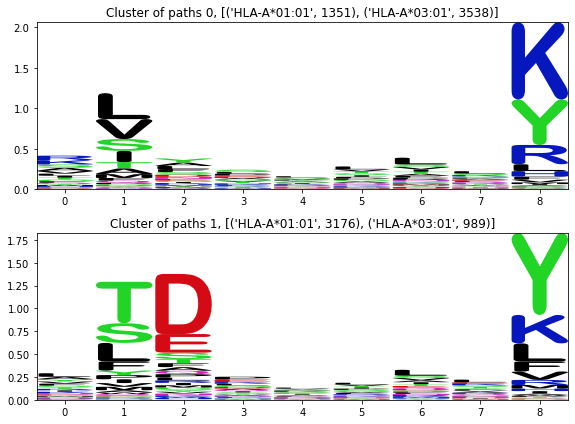

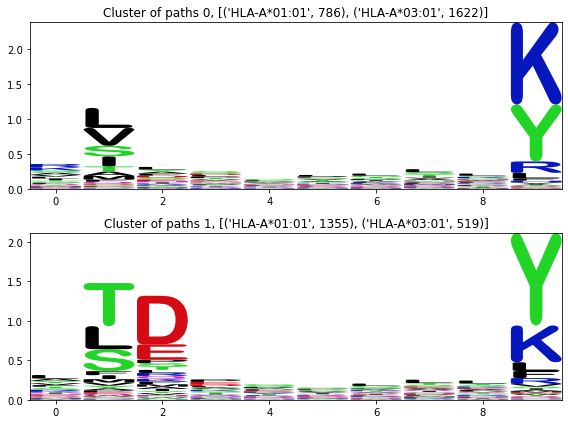

In [17]:
import matplotlib.pyplot as plt
import logomaker
for target_length in TARGET_LENGTHS:
    fig, axes = plt.subplots(nrows=len(unique_labels_counts), figsize=(8, 3*len(unique_labels_counts)))
    for i, label in enumerate(sorted(unique_labels_counts.index)):
        target_label = f'path_gr_{label}'
        print(i)
        # filtered_df =  peptide_df.sort_values(by=f'path_gr_{label}', ascending=False)[:400]
        filtered_df =  peptide_df[peptide_df['max_label'] == target_label]
        filtered_df = filtered_df[filtered_df['len'] == target_length]
        # filtered_df =  filtered_df.sort_values(by=target_label, ascending=False)[:1000]
        counts = filtered_df['allele'].value_counts()


        matrix = logomaker.alignment_to_matrix(filtered_df['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[i])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        counts = [(key, value) for key, value in sorted(counts.items())]
        ww_logo.ax.set_title(f"Cluster of paths {label}, {counts}")
    plt.tight_layout()


## Make PCA and save to file 

In [18]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_cols=["allele","dataset", "label", "peptide"],  whiten=True):
    X = df_concat.drop(columns=target_cols, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_cols=["allele","dataset", "label", "peptide"]):
    X = data.drop(columns=target_cols, errors='ignore').values
    print(f"Shape of X {X.shape}")
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df



def collect_embeddings_with_pca_or_without(train_data, test_data, pca):
    columns_to_drop = ["dataset", "allele", "label", "peptide"]
    if pca:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
        train_embedding = get_pca_embedding(pca, train_embedding)
        test_embedding = get_pca_embedding(pca, test_embedding)
    else:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
        
    if "allele" in train_data.columns:
        alleles_train = train_data['allele'].values
        alleles_test = test_data['allele'].values


    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    train_df['allele'] = alleles_train
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    test_df['allele'] = alleles_test

    total_embedding = pd.concat([train_df, test_df])
    return total_embedding


def get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v):
    per_model_embedding_result= dict()
    for model_key in ['bw', 'bwv', 'v']:
        if model_key == 'bw':
            model_name = 'bw'
            pca = pca_bw
        elif model_key == 'bwv':
            model_name = 'bwv'
            pca = pca_bwv
        else:
            model_name = 'v'
            pca = pca_v

        train_repr = per_model_type_train_embeddings[model_name].copy()
        test_repr = per_model_type_test_embeddings[model_name].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        total_embedding = pd.concat([total_embedding_db])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [19]:
pca_bw = get_pca(pd.concat([per_model_type_train_embeddings['bw']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_model_type_train_embeddings['bwv']]), n_components=15)
pca_v = get_pca(pd.concat([per_model_type_train_embeddings['v']]), n_components=15)

Shape (13336, 1533)
Explained variation per principal component: [0.47722481 0.18361003 0.11745937 0.08075671 0.03242364 0.02759617
 0.01343258 0.00957819 0.00772123 0.00676738 0.00620629 0.00564424
 0.00504734 0.0039243  0.00363993]
Shape (13336, 1593)
Explained variation per principal component: [0.16115078 0.12973162 0.09853478 0.09400185 0.0809657  0.05728522
 0.04823107 0.04324135 0.03623771 0.03346074 0.02977903 0.02734187
 0.02541436 0.02046667 0.01778725]
Shape (13336, 2000)
Explained variation per principal component: [0.30040458 0.08995131 0.06805011 0.0592566  0.05083202 0.04415237
 0.03822903 0.03512896 0.02873223 0.02483173 0.02241762 0.01907611
 0.01726457 0.01596929 0.01505516]


## Variance ratio for pca

In [20]:
pca_bw.explained_variance_ratio_

array([0.47722481, 0.18361003, 0.11745937, 0.08075671, 0.03242364,
       0.02759617, 0.01343258, 0.00957819, 0.00772123, 0.00676738,
       0.00620629, 0.00564424, 0.00504734, 0.0039243 , 0.00363993])

Text(0.5, 0.98, 'PCA explained variance plots')

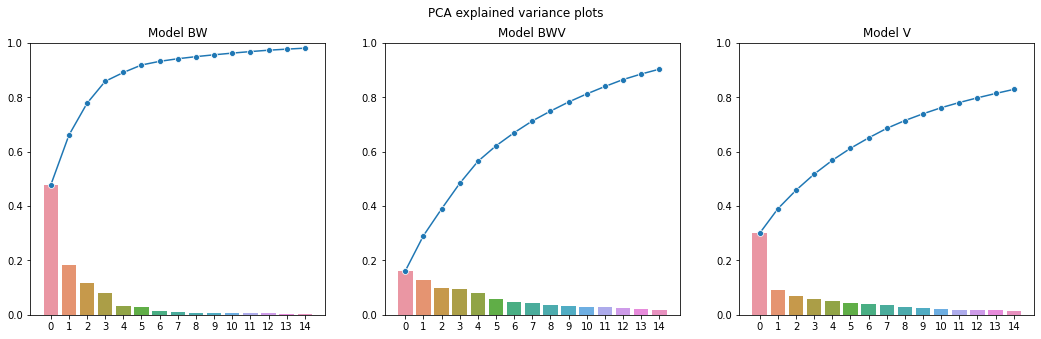

In [21]:
import numpy as np

fig, axes = plt.subplots(nrows=1, ncols= 3, figsize=(18, 5))

ax = sns.barplot(x=np.arange(0, len(pca_bw.explained_variance_ratio_)), y=pca_bw.explained_variance_ratio_, ax=axes[0])
ax.set(ylim=(0, 1))
ax.set_title('Model BW')
ax = sns.lineplot(x=np.arange(0, len(pca_bw.explained_variance_ratio_)), y=np.cumsum(pca_bw.explained_variance_ratio_),  marker="o",ax=axes[0])


ax = sns.barplot(x=np.arange(0, len(pca_bwv.explained_variance_ratio_)), y=pca_bwv.explained_variance_ratio_, ax=axes[1])
ax.set(ylim=(0, 1))
ax.set_title('Model BWV')
ax = sns.lineplot(x=np.arange(0, len(pca_bwv.explained_variance_ratio_)), y=np.cumsum(pca_bwv.explained_variance_ratio_), marker="o",ax=axes[1])


ax = sns.barplot(x=np.arange(0, len(pca_v.explained_variance_ratio_)), y=pca_v.explained_variance_ratio_, ax=axes[2])
ax.set(ylim=(0, 1))
ax.set_title('Model V')
ax = sns.lineplot(x=np.arange(0, len(pca_v.explained_variance_ratio_)), y=np.cumsum(pca_v.explained_variance_ratio_),  marker="o",ax=axes[2])

fig.suptitle("PCA explained variance plots")

In [22]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v)

Shape of X (13336, 1533)
Shape of X (3564, 1533)
Shape of X (13336, 1593)
Shape of X (3564, 1593)
Shape of X (13336, 2000)
Shape of X (3564, 2000)
Wall time: 2.6 s


In [23]:
per_model_embedding_result['bw'].head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,dataset,allele
SFDIQLTSV,-0.257016,1.018860,0.357554,-1.692488,0.591316,-0.475984,-0.846784,2.372135,0.841274,-1.192860,0.503316,1.131905,0.024194,0.220708,0.080238,Train_db,HLA-A*01:01
TTEILRSML,-0.228162,0.786573,-0.369067,-1.718256,0.272125,0.411105,1.016529,-0.524965,-0.060094,-1.217032,0.338465,0.315667,0.161545,-2.666579,-0.269751,Train_db,HLA-A*01:01
ALNDTWKMEK,1.584118,-0.869437,-0.567417,-0.836252,0.986921,-1.297688,0.426993,-1.220090,-0.064428,0.267726,0.477154,0.538173,-0.557358,0.306020,0.129703,Train_db,HLA-A*03:01
ALAAAAAAAK,-0.387256,-0.781633,-0.865041,-0.956495,-0.832998,-0.794790,0.050360,-0.296567,0.132243,0.200866,0.704392,1.922090,-0.954054,-0.375269,0.638986,Train_db,HLA-A*03:01
LYDKDAVYV,0.697460,1.684684,-0.294156,-0.980262,-0.293277,0.363791,1.575504,2.356290,1.482155,0.305703,-0.242814,-0.262677,1.227809,0.967601,0.308408,Train_db,HLA-A*01:01


## Save to files

In [24]:
def save_pca(total_embedding, model):
    train_embedding = total_embedding[total_embedding['dataset'] == 'Train_db']
    test_embedding = total_embedding[total_embedding['dataset'] == 'Test_db']
    
    print(f"model {model}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model] + model
    assert total_embedding['allele'].isnull().sum() == 0
    train_embedding.to_csv("{}/train_pca.csv".format(TARGET_PATH_TO_FILES),sep=";", index=True)
    test_embedding.to_csv("{}/test_pca.csv".format(TARGET_PATH_TO_FILES),sep=";", index=True)

In [25]:
save_pca(per_model_embedding_result['bw'], mixed_model_bw)
save_pca(per_model_embedding_result['bwv'], mixed_model_bwv)
save_pca(per_model_embedding_result['v'], mixed_model_v)


model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0


# Mak UMAP of pca and save to file

## Make UMAP object

In [26]:
import umap
from sklearn.preprocessing import StandardScaler
from collections import defaultdict
import matplotlib.pyplot as plt

def get_reducer(data,n_neighbors=15, n_components=2):
    reducer = umap.UMAP(n_neighbors=n_neighbors, n_components=n_components)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_umap_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    umap_result = reducer.transform(scaled_data)
    df = pd.DataFrame(umap_result, index=data.index)
    return df


def define_pallete(df, hue_column):
    unique_hue_values = sorted(df[hue_column].unique())
    source_pallete = sns.color_palette("hls", len(unique_hue_values))
    colors ={hue_value: source_pallete[i] for i, hue_value in enumerate(unique_hue_values)}
    return colors

def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)
    return fig


## Calculate UMAP

model bw
model bwv
model v
Wall time: 2min 14s


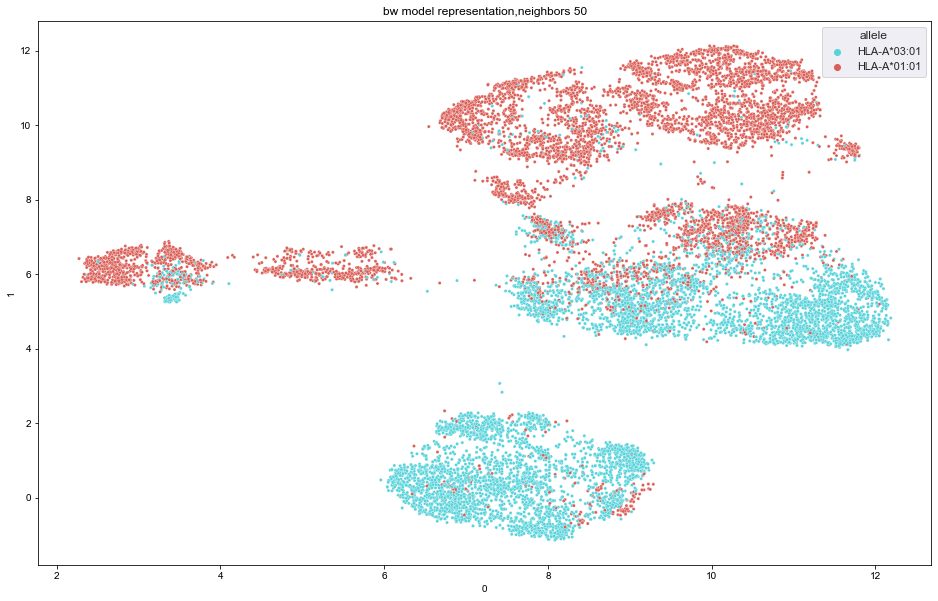

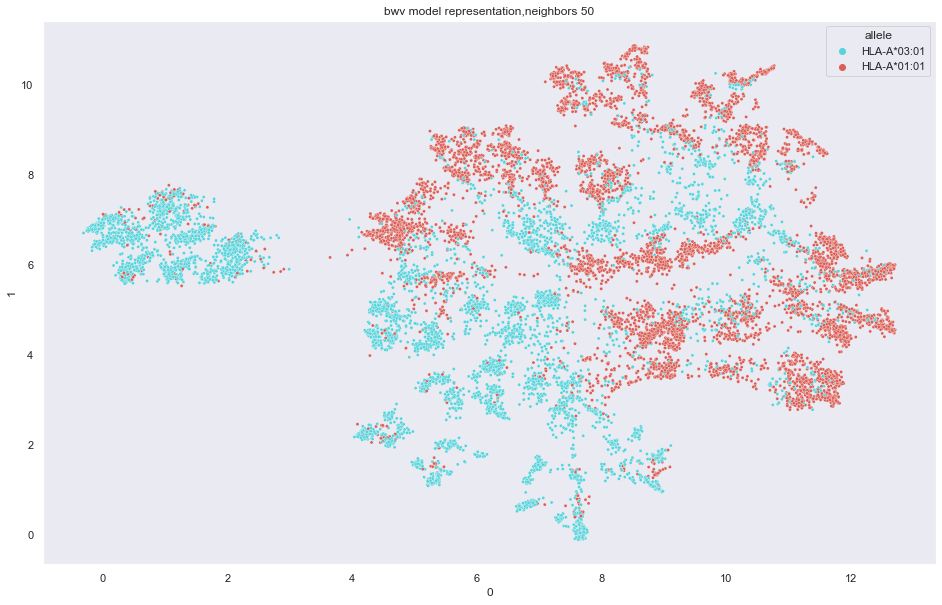

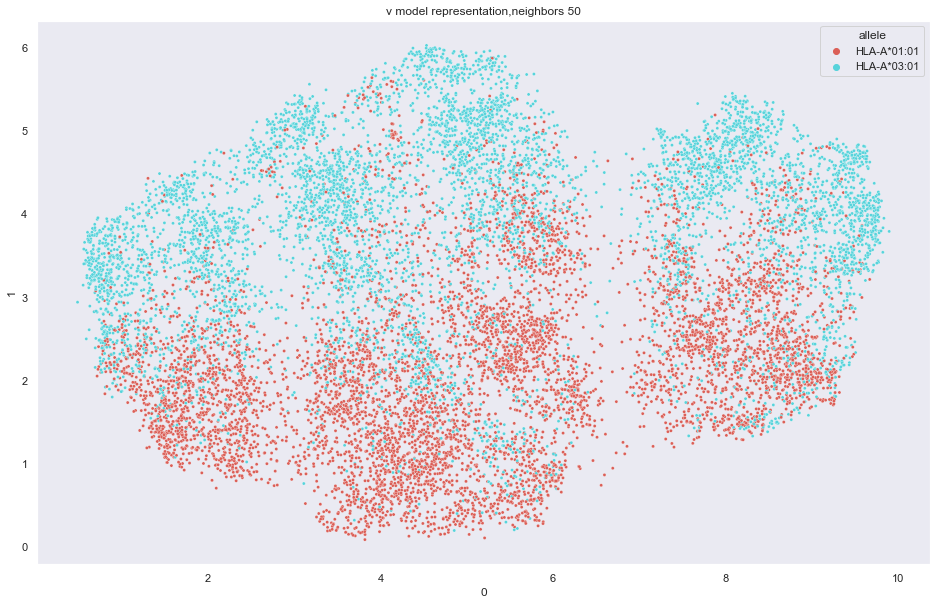

In [27]:
%%time
n = 50

train_embedding_bw = None
train_embedding_bwv = None
train_embedding_v= None

test_embedding_bw = None
test_embedding_bwv = None
test_embedding_v= None

for model, total_model_df in per_model_embedding_result.items():
    print(f"model {model}")
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    test_df = total_model_df[total_model_df['dataset'] == f'Test_db']

    train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    test_data = test_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)
    train_embedding = get_umap_embedding(reducer_b, scaler_b, train_data)
    train_embedding['allele'] = train_df['allele']
    train_embedding['dataset'] = train_df['dataset']
    train_embedding['length'] = train_embedding.index.str.len()
    test_embedding = get_umap_embedding(reducer_b, scaler_b, test_data)
    test_embedding['allele'] = test_df['allele']
    test_embedding['dataset'] = test_df['dataset']
    test_embedding['length'] = test_embedding.index.str.len()
    if model == "bw":
        train_embedding_bw = train_embedding
        test_embedding_bw = test_embedding
    elif model == 'bwv':
        train_embedding_bwv = train_embedding
        test_embedding_bwv = test_embedding
    elif model == 'v':
        train_embedding_v = train_embedding
        test_embedding_v = test_embedding

    fig = make_scatter_plot_sns(train_embedding, title=f"{model} model representation,neighbors {n}", hue_column='allele')

## Analyze motifs

In [28]:
def make_logo(df, length=9):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = df['allele'].value_counts()
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f" Allele counts: {counts}")

def select_rectangle(df, x1, x2, y1, y2):
    filtered_df = df[(df[0] > x1) & (df[0] < x2) & (df[1] > y1) & (df[1] < y2)]
    filtered_df['peptide'] = filtered_df.index
    return filtered_df


In [29]:
counts = train_embedding['allele'].value_counts()
counts

HLA-A*01:01    6668
HLA-A*03:01    6668
Name: allele, dtype: int64

In [147]:
train_embedding = train_embedding_v
filtered_1 = select_rectangle(train_embedding, 0, 4, 0, 8)
filtered_2 = select_rectangle(train_embedding, 5, 7, 0, 5.2)

filtered_3 = select_rectangle(train_embedding, 6.1, 10, 5, 7.5)
filtered_4 = select_rectangle(train_embedding, 3, 8, 8, 15)

# #
# #
filtered_5 = select_rectangle(train_embedding, 4, 6, 5.5, 7.5)
filtered_6 = select_rectangle(train_embedding, 3.2, 4, 0, 7.5)
# #

C:\Users\denkl\AppData\Local\Temp/ipykernel_25764/2837600045.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['peptide'] = filtered_df.index


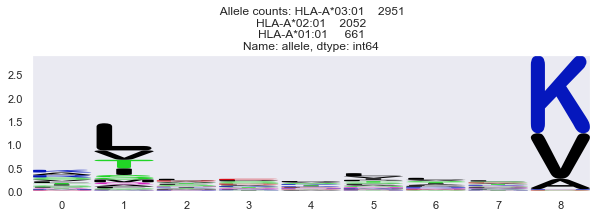

In [148]:
make_logo(filtered_1) # ... 

## Save to file

In [69]:
def save_umap(embedding, model, type_of_data="train", dataset='bw'):
    print(f"model {model}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model] + model
    assert train_embedding['allele'].isnull().sum() == 0
    embedding.to_csv("{}/{}_{}_umap.csv".format(TARGET_PATH_TO_FILES,dataset, type_of_data),sep=";", index=True)
    


In [70]:
save_umap(train_embedding_bw, mixed_model_bw, type_of_data="train",dataset='bw')
save_umap(test_embedding_bw, mixed_model_bw, type_of_data="test", dataset='bw')

save_umap(train_embedding_bwv, mixed_model_bwv, type_of_data="train", dataset='bwv')
save_umap(test_embedding_bwv, mixed_model_bwv, type_of_data="test", dataset='bwv')

save_umap(train_embedding_v, mixed_model_v, type_of_data="train", dataset='v')
save_umap(test_embedding_v, mixed_model_v, type_of_data="test", dataset='v')



model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0


## Per length picture

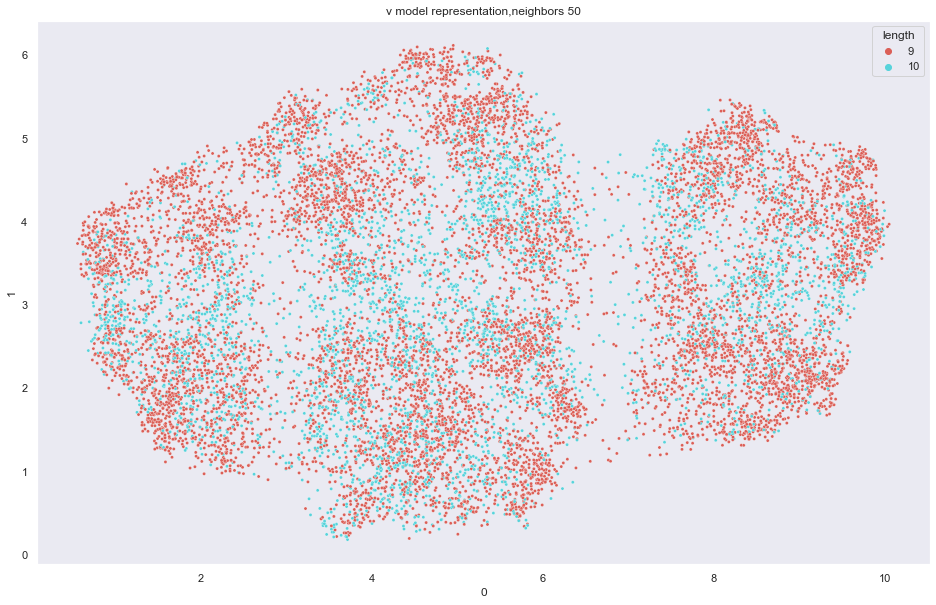

In [71]:
fig = make_scatter_plot_sns(train_embedding_v, title=f"{model} model representation,neighbors {n}", hue_column='length')

## Cluster pictures

In [30]:
train_data = train_embedding_v
test_data = test_embedding_v

In [31]:
train_data

,0,1,allele,dataset,length
SFDIQLTSV,5.674776,0.630098,HLA-A*01:01,Train_db,9
TTEILRSML,2.200821,1.553176,HLA-A*01:01,Train_db,9
ALNDTWKMEK,4.382519,2.266145,HLA-A*03:01,Train_db,10
ALAAAAAAAK,4.781884,1.925808,HLA-A*03:01,Train_db,10
LYDKDAVYV,1.710657,1.282222,HLA-A*01:01,Train_db,9
...,...,...,...,...,...
FIFQSSMTK,4.769863,5.729836,HLA-A*03:01,Train_db,9
QLYKEQLAK,9.620810,3.806032,HLA-A*03:01,Train_db,9
LLNRPLWAK,9.309269,4.796429,HLA-A*03:01,Train_db,9
KVPVVLLKK,8.905564,4.930788,HLA-A*03:01,Train_db,9


In [ ]:
def clustering_experiment(cluster_counts):
    """
        Train will be used for training
        All other datasets will be fitted
    """
    train_data_dict = {
        "bw":train_embedding_bw,
        "bwv": train_embedding_bwv,
        "v":train_embedding_v
    }
    test_data_dict = {
        "bw": test_embedding_bw,
        "bwv": test_embedding_bwv,
        "v": test_embedding_v
    }
    
    per_cluster_count_result = dict()
    

    for cluster_count in cluster_counts:
        per_model_kmeans = dict()
        print(f"cluster_count {cluster_count}")
        for model_key in train_data_dict.keys():
            kmeans = KMeans(n_clusters=cluster_count)
            train_data = train_data_dict[model_key]
            train_data = train_data.drop(columns=["dataset", "peptide", "allele", "length"],  errors='ignore').values
            kmeans.fit(train_data)
            per_model_kmeans[model_key] =
        # bw
        kmeans_bw = KMeans(n_clusters=cluster_count)
        train_data = train_embedding_bw
        train_data = train_data.drop(columns=["dataset", "peptide", "allele", "length"],  errors='ignore').values
        kmeans_bw.fit(train_data)
        # bwv
        kmeans_bwv = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bwv'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bwv.fit(train_data)

        # bwv
        kmeans_v = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['v'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide","allele"],  errors='ignore').values
        kmeans_v.fit(train_data)
        # # immmune model
        # total_model_df = total_embedding_df['mi'].copy()
        # kmeans_i = KMeans(n_clusters= cluster_count)
        # #extract train_data ensure no peptide columns
        # train_df =total_model_df[total_model_df['dataset'] == f'Train_di']
        # train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        # kmeans_i.fit(train_data)

        total_clustering_result = cluster_total_embedding(total_embedding_df, {"bw":kmeans_bw , "bwv":kmeans_bwv, "v": kmeans_v})
        per_cluster_count_result[cluster_count] = total_clustering_result
    return per_cluster_count_result

# Some old alanysis just for history

# Test clustering approaches
## Run PCA  first (as it's suggested by K-Means)
### Get pca objects

In [36]:
per_name_representation_train['v']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,allele,label
PVSMTYLYNK,-0.767756,-1.088749,-1.088269,-1.136451,-1.110482,-1.126951,-0.866452,-0.985360,-0.735749,-0.874844,...,-1.145076,-1.230186,-1.147024,-0.874245,-1.095748,-1.457219,-1.120143,-1.239554,HLA-A*03:01,1
NYDLALKYF,-1.133209,-0.807913,-0.938645,-0.989824,-1.055381,-0.980324,-1.221345,-1.072828,-1.225003,-1.003204,...,-0.936420,-0.907656,-1.070104,-1.219688,-1.100022,-1.130287,-1.023211,-1.052718,HLA-A*01:01,0
TLKSFTVEK,-1.045980,-1.164910,-1.164430,-1.309880,-1.180526,-1.442628,-1.052648,-1.166878,-1.043307,-1.047711,...,-1.336272,-1.034953,-1.058531,-1.171488,-1.067980,-1.081329,-1.393245,-1.207510,HLA-A*03:01,1
AIFTDASTV,-1.062561,-0.941709,-0.941229,-0.655181,-0.822113,-0.645681,-1.069229,-1.062961,-1.006282,-0.945006,...,-0.834980,-0.810637,-0.835843,-0.821074,-0.946041,-1.074098,-0.576180,-0.962399,HLA-A*02:01,2
KLEYLAPSY,-1.049917,-0.929065,-0.928585,-0.919620,-0.980604,-1.052369,-0.925646,-1.050318,-1.060243,-0.932363,...,-1.184716,-0.893841,-0.919782,-1.054928,-1.011185,-1.143730,-1.156217,-1.098082,HLA-A*01:01,0


In [37]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_cols=["allele","dataset", "label"],  whiten=True):
    X = df_concat.drop(columns=target_cols, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_cols=["allele","dataset", "label"]):
    X = data.drop(columns=target_cols, errors='ignore').values
    print(f"Shape of X {X.shape}")
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df




In [38]:
pca_bw = get_pca(pd.concat([per_name_representation_train['bw']['db']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_name_representation_train['bwv']['db']]), n_components=15)
pca_v = get_pca(pd.concat([per_name_representation_train['v']['db']]), n_components=15)

Shape (20234, 1518)
Explained variation per principal component: [0.35394269 0.23587922 0.10104998 0.06258665 0.03244827 0.02813503
 0.02620156 0.02189285 0.01944591 0.01761573 0.012354   0.01153913
 0.01045792 0.00939453 0.00877473]
Shape (20234, 862)
Explained variation per principal component: [0.16391172 0.16114598 0.12877053 0.09399624 0.07988388 0.05734928
 0.05676028 0.04665017 0.03450371 0.03296763 0.03177579 0.02852508
 0.01591615 0.01296891 0.01113115]
Shape (20234, 2000)
Explained variation per principal component: [0.22852142 0.09858035 0.09364597 0.07301351 0.05111895 0.04725978
 0.04057294 0.0359668  0.03514807 0.029157   0.0243041  0.02106872
 0.02026886 0.01762114 0.01541918]


<AxesSubplot:>

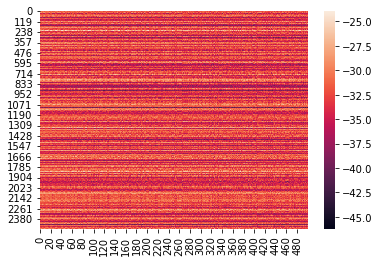

In [44]:
sns.heatmap(per_name_representation_test['bw']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

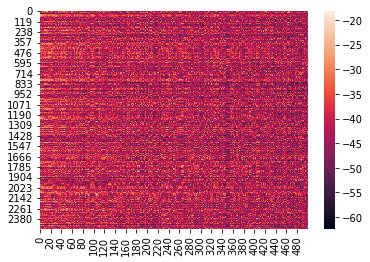

In [45]:
sns.heatmap(per_name_representation_test['bwv']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

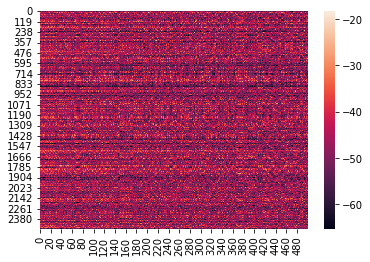

In [46]:
sns.heatmap(per_name_representation_test['v']['db'].drop(columns=["allele"]).values)

In [39]:
df = per_name_representation_train['bwv']['db'].drop(columns=["allele"]).copy().T

In [40]:
def collect_embeddings_with_pca_or_without(train_data, test_data, pca):
    columns_to_drop = ["dataset", "allele", "label"]
    if pca:
        train_embedding = get_pca_embedding(pca, train_data)
        test_embedding = get_pca_embedding(pca, test_data)
    else:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
    if "allele" in train_data.columns:
        alleles_train = train_data['allele'].values
        alleles_test = test_data['allele'].values


    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    train_df['allele'] = alleles_train
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    test_df['allele'] = alleles_test

    total_embedding = pd.concat([train_df, test_df])
    return total_embedding

In [41]:
def get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v):
    per_model_embedding_result= dict()
    for model_key in ['bw', 'bwv', 'v']:
        if model_key == 'bw':
            model_name = 'bw'
            pca = pca_bw
        elif model_key == 'bwv':
            model_name = 'bwv'
            pca = pca_bwv
        else:
            model_name = 'v'
            pca = pca_v

        train_repr = per_name_representation_train[model_name]['db'].copy()
        test_repr = per_name_representation_test[model_name]['db'].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        total_embedding = pd.concat([total_embedding_db])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [42]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v)
# per_model_embedding_result_w = get_embedding_for_selected_models_using_pca(pca_b_w, pca_i_w)

Shape of X (20234, 1518)
Shape of X (5328, 1518)
Shape of X (20234, 862)
Shape of X (5328, 862)
Shape of X (20234, 2000)
Shape of X (5328, 2000)
Wall time: 8.75 s


In [47]:
per_model_embedding_result_without_pca['bw'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,Train_db,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,Train_db,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,Train_db,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,Train_db,HLA-A*03:01


In [48]:
per_model_embedding_result_without_pca['bwv'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.375824,-0.458435,-0.438305,-0.462972,-0.399262,-0.375359,-0.307893,-0.396597,-0.424391,-0.526497,...,-0.690939,-0.748143,-0.797170,-0.690649,-0.696509,-0.549402,-0.656650,-0.580109,Train_db,HLA-A*02:01
YLGPRVCWL,-0.375384,-0.375884,-0.318415,-0.453251,-0.469359,-0.384728,-0.410935,-0.332883,-0.527944,-0.381633,...,-0.512078,-0.637890,-0.651993,-0.668445,-0.778125,-0.581005,-0.543768,-0.582657,Train_db,HLA-A*02:01
QTCLELERY,-0.490758,-0.573580,-0.576579,-0.549482,-0.576087,-0.584300,-0.417656,-0.526961,-0.325174,-0.647071,...,-0.732136,-0.849313,-0.788534,-0.601646,-0.662889,-0.646481,-0.783966,-0.643668,Train_db,HLA-A*01:01
YTIERIFNAK,-0.470495,-0.553105,-0.628358,-0.386680,-0.564470,-0.555947,-0.510853,-0.503916,-0.348079,-0.556329,...,-0.557415,-0.681102,-0.640245,-0.638204,-0.625053,-0.591918,-0.765382,-0.705399,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.507488,-0.507989,-0.432012,-0.592135,-0.530785,-0.420424,-0.549782,-0.379522,-0.602320,-0.366064,...,-0.568634,-0.643238,-0.670440,-0.651408,-0.634305,-0.561511,-0.578042,-0.655989,Train_db,HLA-A*03:01


In [49]:
per_name_representation_train['bw']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.413016,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.408443,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.445261,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.426974,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.458310,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,HLA-A*03:01


In [43]:
from collections import defaultdict
from sklearn.cluster import KMeans

def cluster_total_embedding(total_embedding_dfs, per_model_predictor):
    total_clustering_result = defaultdict(list)
    for m_key in total_embedding_dfs.keys():
        # print(f"model_key {m_key}")
        total_model_df =  total_embedding_dfs[m_key].copy()
        representation_df = total_model_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
        representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
        representation_df['dataset'] = total_model_df['dataset']

        total_clustering_result[m_key] = representation_df

    return total_clustering_result

In [44]:
def clustering_experiment(total_embedding_df, cluster_counts):
    """
        Train will be used for training
        All other datasets will be fitted
    """

    per_cluster_count_result = dict()
    for cluster_count in cluster_counts:
        print(f"cluster_count {cluster_count}")
        # bw
        kmeans_bw = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bw'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bw.fit(train_data)
        # bwv
        kmeans_bwv = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bwv'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bwv.fit(train_data)

        # bwv
        kmeans_v = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['v'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide","allele"],  errors='ignore').values
        kmeans_v.fit(train_data)
        # # immmune model
        # total_model_df = total_embedding_df['mi'].copy()
        # kmeans_i = KMeans(n_clusters= cluster_count)
        # #extract train_data ensure no peptide columns
        # train_df =total_model_df[total_model_df['dataset'] == f'Train_di']
        # train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        # kmeans_i.fit(train_data)

        total_clustering_result = cluster_total_embedding(total_embedding_df, {"bw":kmeans_bw , "bwv":kmeans_bwv, "v": kmeans_v})
        per_cluster_count_result[cluster_count] = total_clustering_result
    return per_cluster_count_result

In [45]:
cluster_counts = [2 , 4,  5]
per_cluster_count_result_pca = clustering_experiment(per_model_embedding_result, cluster_counts=cluster_counts)
per_cluster_count_result_repr = clustering_experiment(per_model_embedding_result_without_pca, cluster_counts=cluster_counts)

cluster_count 2
cluster_count 4
cluster_count 5
cluster_count 2
cluster_count 4
cluster_count 5


## Plot PCA plots

3    3794
0    3145
1    2168
2    1940
4     686
Name: label, dtype: int64


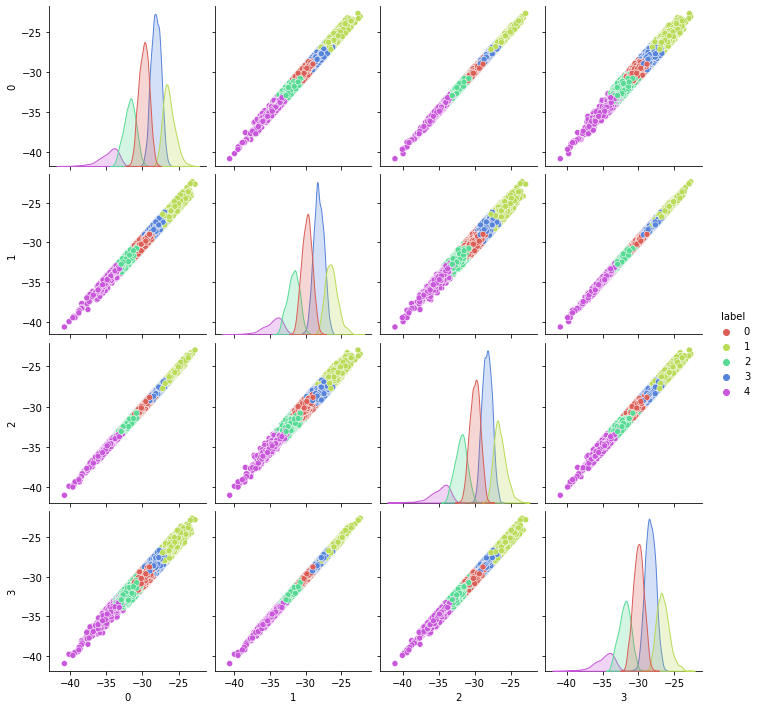

In [108]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))


4    3045
0    2433
2    2372
1    2096
3    1787
Name: label, dtype: int64


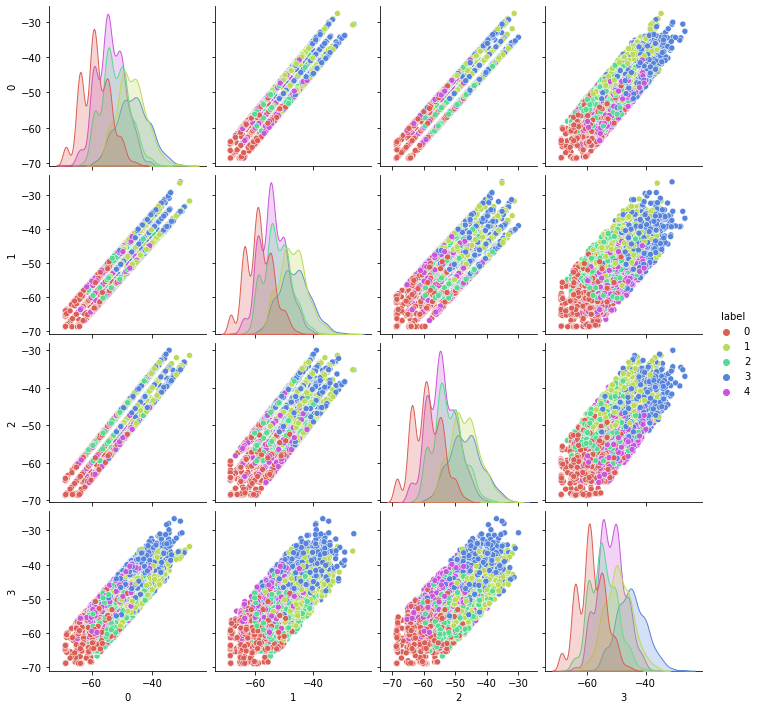

In [109]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

2    3511
0    3262
3    2737
1    1207
4    1016
Name: label, dtype: int64


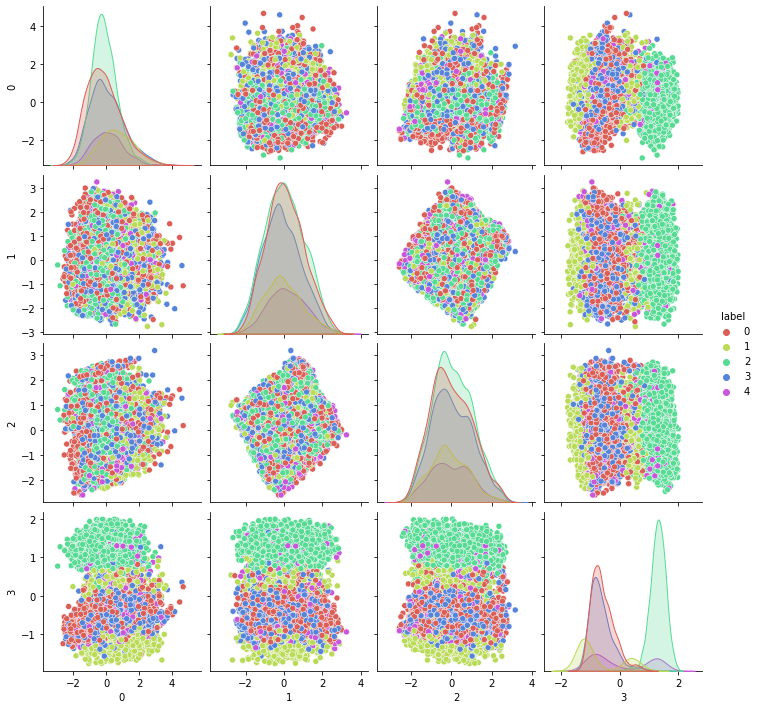

In [57]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4276
4    3622
0    3598
3    3176
2    2798
Name: label, dtype: int64


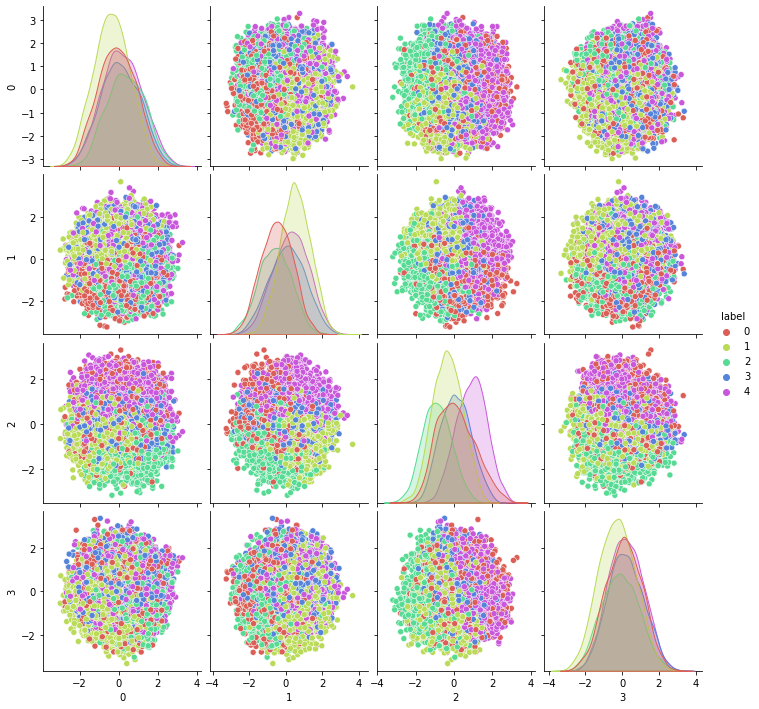

In [68]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4152
3    2817
4    2705
2    1567
0     492
Name: label, dtype: int64


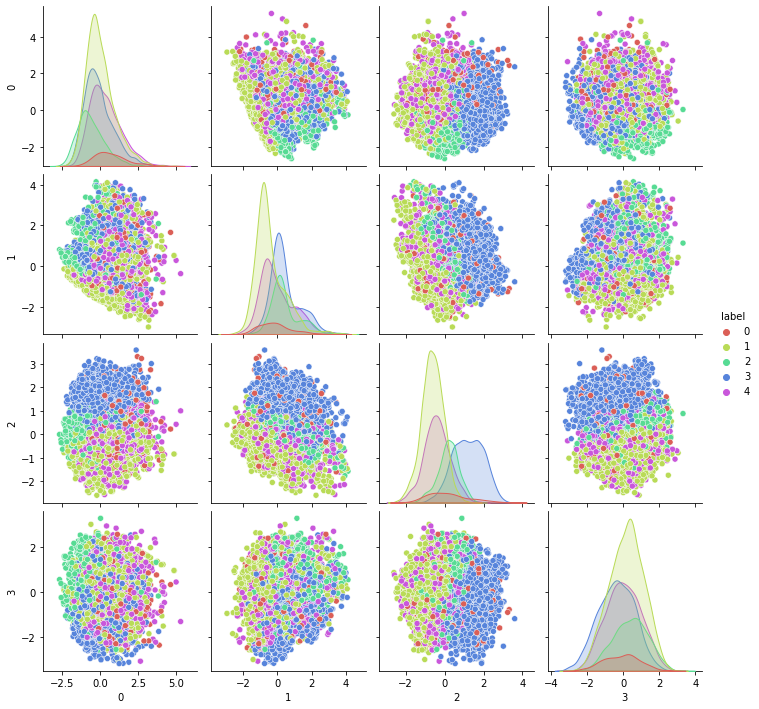

In [86]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bwv']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

In [96]:
df

,0,1,2,3,label
0,0.999295,0.387324,0.678455,-0.490383,3
1,0.108097,0.021062,0.669517,1.430231,3
2,-0.489513,0.130982,2.365413,-0.590073,0
3,0.476359,-0.651274,1.616374,-0.909632,0
4,0.215536,1.019187,-1.049684,0.503872,4
...,...,...,...,...,...
11728,1.826773,0.694532,-0.540280,0.434760,0
11729,1.655829,0.138762,-0.061199,2.225898,3
11730,-0.679647,-1.219310,-0.063222,1.409131,1
11731,0.944976,-0.191033,0.393523,1.156476,3
